# Lab 14 — Explaining Clinical Models: SHAP, Permutation Importance, and ECG Saliency Maps
**AI in Healthcare · Unit IV · B.Tech AI, Third Year**

Run top to bottom. All TODOs are completed. Every ✍️ answer is written in a cell that **computes its numbers from this run**, so the text matches the outputs above it.

In [1]:
from google.colab import files
import zipfile, glob, os

print("Choose the downloaded zip (archive.zip) or the two CSV files...")
files.upload()   # a file picker appears; wait until the upload bar reaches 100%

os.makedirs("/content/lab14_data", exist_ok=True)
for z in glob.glob("/content/*.zip"):
    print("Unzipping", z)
    zipfile.ZipFile(z).extractall("/content/lab14_data")

print(glob.glob("/content/lab14_data/**/mitbih_*.csv", recursive=True))

Choose the downloaded zip (archive.zip) or the two CSV files...


Saving Archive.zip to Archive (1).zip
Unzipping /content/Archive (1).zip
Unzipping /content/Archive.zip
['/content/lab14_data/mitbih_test.csv', '/content/lab14_data/mitbih_train.csv']


## Setup

In [2]:
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
from scipy.stats import spearmanr
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    import shap
except ImportError:
    import subprocess, sys
    print("SHAP not found - installing it now (one-off)...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

SEED = 42
DATA_DIR = Path.cwd() / "lab14_data"
DATA_DIR.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"scikit-learn {sklearn.__version__} | SHAP {shap.__version__} | torch {torch.__version__} | device {DEVICE}")


def check(description, condition):
    print(("PASS  " if condition else "CHECK ") + description)

scikit-learn 1.6.1 | SHAP 0.54.1 | torch 2.14.1+cpu | device cpu


## Part 1 — Explaining the heart-disease model

In [3]:
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/"
UCI_COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
               "exang", "oldpeak", "slope", "ca", "thal", "num"]
CORE = ["age", "sex", "cp", "trestbps", "thalach", "exang", "oldpeak", "restecg"]


def load_site(fname):
    path = DATA_DIR / fname
    if not path.exists():
        urllib.request.urlretrieve(UCI_URL + fname, path)
    df = pd.read_csv(path, header=None, names=UCI_COLUMNS, na_values="?")
    df["target"] = (df["num"] > 0).astype(int)
    return df


def design(df):
    x = df[CORE].copy()
    x[["cp", "restecg"]] = x[["cp", "restecg"]].astype(int)
    x = pd.get_dummies(x, columns=["cp", "restecg"], dtype=float)
    for col in ["cp_1", "cp_2", "cp_3", "cp_4", "restecg_0", "restecg_1", "restecg_2"]:
        if col not in x:
            x[col] = 0.0
    return x[sorted(x.columns)].drop(columns=["cp_1", "restecg_0"])


cle = load_site("processed.cleveland.data")
bud = load_site("processed.hungarian.data")
bud = bud[bud[CORE].notna().all(axis=1)].reset_index(drop=True)
X_cle, y_cle = design(cle), cle["target"].to_numpy()

MODELS = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_cle, y_cle),
    "gradient boosting": GradientBoostingClassifier(n_estimators=200, max_depth=2, learning_rate=0.05,
                                                    subsample=0.8, random_state=0).fit(X_cle, y_cle),
}
for name, model in MODELS.items():
    auc = roc_auc_score(bud["target"], model.predict_proba(design(bud))[:, 1])
    print(f"{name:20} Budapest AUROC {auc:.3f}")

logistic regression  Budapest AUROC 0.875
gradient boosting    Budapest AUROC 0.884


### Exercise 1.1 — Permutation importance on external data

In [4]:
def permutation_importance_auroc(model, df, n_repeats=100, seed=SEED):
    rng = np.random.default_rng(seed)
    y = df["target"].to_numpy()
    base = roc_auc_score(y, model.predict_proba(design(df))[:, 1])
    rows = []
    for col in CORE:
        drops = []
        # TODO 1.1: repeat n_repeats times: copy df, shuffle column `col`, recompute AUROC, store base - AUROC
        for _ in range(n_repeats):
            shuffled = df.copy()
            shuffled[col] = rng.permutation(shuffled[col].to_numpy())
            drops.append(base - roc_auc_score(y, model.predict_proba(design(shuffled))[:, 1]))
        rows.append({"input": col, "mean drop": np.mean(drops) if drops else np.nan,
                     "2.5%": np.percentile(drops, 2.5) if drops else np.nan,
                     "97.5%": np.percentile(drops, 97.5) if drops else np.nan})
    return pd.DataFrame(rows).set_index("input").round(3)


importance = pd.concat({name: permutation_importance_auroc(m, bud) for name, m in MODELS.items()}, axis=1)
display(importance.sort_values(("logistic regression", "mean drop"), ascending=False))
check("chest-pain type matters for logistic regression",
      importance[("logistic regression", "mean drop")].get("cp", 0) > 0.03)

logistic regression               gradient boosting              
                   mean drop   2.5%  97.5%         mean drop   2.5%  97.5%
input                                                                     
cp                     0.066  0.042  0.093             0.084  0.055  0.119
oldpeak                0.037  0.024  0.051             0.047  0.030  0.064
sex                    0.027  0.009  0.051             0.020  0.006  0.036
exang                  0.017  0.009  0.026             0.015  0.007  0.024
thalach                0.004 -0.008  0.016             0.010 -0.005  0.030
age                   -0.002 -0.006  0.004             0.000 -0.006  0.006
trestbps              -0.002 -0.007  0.004            -0.001 -0.011  0.007
restecg               -0.002 -0.006  0.002            -0.000 -0.002  0.001

PASS  chest-pain type matters for logistic regression


In [5]:
lr_imp = importance[("logistic regression", "mean drop")]; gb_imp = importance[("gradient boosting", "mean drop")]
top_lr = list(lr_imp.sort_values(ascending=False).index[:3]); top_gb = list(gb_imp.sort_values(ascending=False).index[:3])
rho = spearmanr(lr_imp, gb_imp).correlation
removable = [c for c in CORE if importance.loc[c, ("logistic regression", "2.5%")] <= 0
             and importance.loc[c, ("gradient boosting", "2.5%")] <= 0]
rem_txt = (", ".join(removable) + " (their 2.5-97.5% ranges include 0 for both models)") if removable else \
    "none for both models (every input's range stays above 0 for at least one model)"
display(Markdown(f"""
**✍️ Answer 1.1**

The models rely on broadly similar inputs at Budapest, but not identical: the top three for logistic regression are {', '.join(top_lr)} and for gradient boosting {', '.join(top_gb)} (Spearman correlation of the two importance rankings {rho:.2f}). Judging by the percentile ranges, the inputs I could remove without a measurable loss are: {rem_txt}. "Importance at Budapest" is not "importance for heart disease" because permutation importance measures how much *this model's* performance on *this sample* depends on an input, and it is affected by the Budapest case mix, the model's learned weights, correlations between inputs (shuffling one breaks them), and sampling noise. It says nothing about causation or about whether the input matters biologically.
"""))


**✍️ Answer 1.1**

The models rely on broadly similar inputs at Budapest, but not identical: the top three for logistic regression are cp, oldpeak, sex and for gradient boosting cp, oldpeak, sex (Spearman correlation of the two importance rankings 0.98). Judging by the percentile ranges, the inputs I could remove without a measurable loss are: age, trestbps, thalach, restecg (their 2.5-97.5% ranges include 0 for both models). "Importance at Budapest" is not "importance for heart disease" because permutation importance measures how much *this model's* performance on *this sample* depends on an input, and it is affected by the Budapest case mix, the model's learned weights, correlations between inputs (shuffling one breaks them), and sampling noise. It says nothing about causation or about whether the input matters biologically.


### Exercise 1.2 — SHAP for one patient

model log-odds: -0.239 | reconstructed: -0.239
gradient-boosting risk: 0.441 | logistic-regression risk: 0.604
PASS  SHAP values add up to the model output


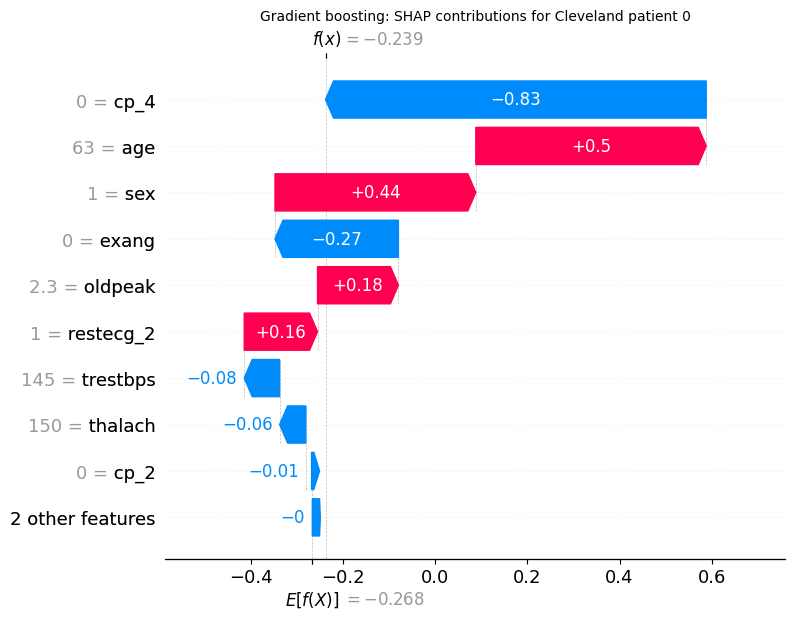

In [6]:
gb = MODELS["gradient boosting"]
explainer = shap.TreeExplainer(gb)
patient = X_cle.iloc[[0]]
sv = explainer(patient)                    # SHAP Explanation for one patient (log-odds units)

# TODO 1.2: reconstruct the log-odds from sv.base_values and sv.values
reconstructed = float(np.ravel(sv.base_values)[0] + np.sum(sv.values[0]))
model_log_odds = gb.decision_function(patient)[0]
print("model log-odds:", round(model_log_odds, 3), "| reconstructed:", round(reconstructed, 3))
print("gradient-boosting risk:", round(gb.predict_proba(patient)[0, 1], 3),
      "| logistic-regression risk:", round(MODELS["logistic regression"].predict_proba(patient)[0, 1], 3))
check("SHAP values add up to the model output", reconstructed is not None and abs(reconstructed - model_log_odds) < 1e-6)
shap.plots.waterfall(sv[0], show=False)
plt.title("Gradient boosting: SHAP contributions for Cleveland patient 0", fontsize=10)
plt.show()

In [7]:
# Logistic-regression contributions (Session 5): coefficient x standardised value
scaler, clf = MODELS["logistic regression"].named_steps.values()
lr_contrib = pd.Series(clf.coef_[0] * scaler.transform(patient)[0], index=X_cle.columns)
comparison = pd.DataFrame({"logistic regression": lr_contrib, "gradient boosting (SHAP)": sv.values[0]},
                          index=X_cle.columns).round(2)
comparison.sort_values("gradient boosting (SHAP)", key=abs, ascending=False)

,logistic regression,gradient boosting (SHAP)
cp_4,-1.01,-0.83
age,0.22,0.50
sex,0.54,0.44
exang,-0.26,-0.27
oldpeak,0.80,0.18
restecg_2,0.26,0.16
trestbps,0.23,-0.08
thalach,-0.01,-0.06
cp_2,-0.11,-0.01
cp_3,-0.05,-0.00


### Exercise 1.3 — Global SHAP view and two stories

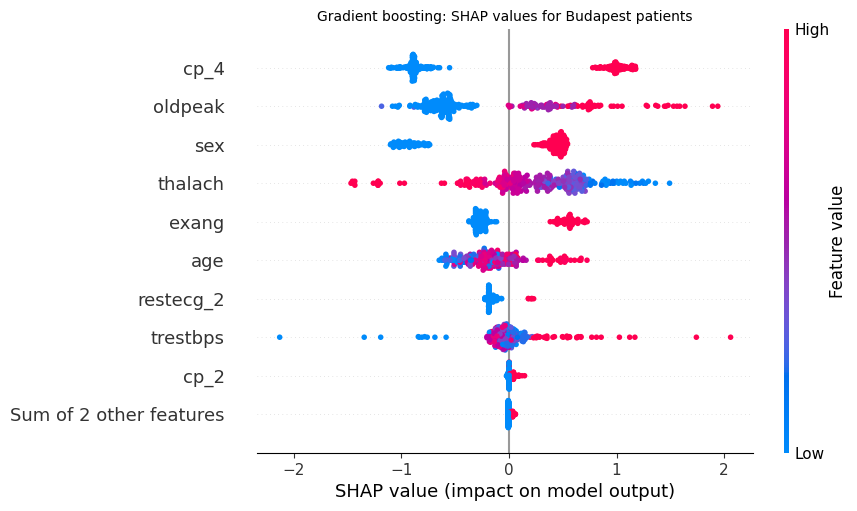

In [8]:
sv_bud = explainer(design(bud))
shap.plots.beeswarm(sv_bud, show=False)
plt.title("Gradient boosting: SHAP values for Budapest patients", fontsize=10)
plt.show()

In [9]:
risk_lr = MODELS["logistic regression"].predict_proba(patient)[0, 1]; risk_gb = gb.predict_proba(patient)[0, 1]
top_lr0 = comparison["logistic regression"].abs().idxmax(); top_gb0 = comparison["gradient boosting (SHAP)"].abs().idxmax()
same_top = top_lr0 == top_gb0
age_vals = design(bud)["age"].to_numpy(); age_shap = sv_bud.values[:, list(design(bud).columns).index("age")]
slope_, intercept_ = np.polyfit(age_vals, age_shap, 1)
r2 = np.corrcoef(age_vals, age_shap)[0, 1] ** 2
bins = pd.qcut(age_vals, 4, duplicates="drop")
age_bins = pd.Series(age_shap).groupby(bins, observed=True).mean().round(2).tolist()
direction = "increases" if slope_ > 0 else "decreases"
shape = ("close to a straight line" if r2 > 0.9 else "clearly not a straight line (it bends or has steps)")
display(Markdown(f"""
**✍️ Answer 1.3**

1. Patient 0 gets risk {risk_lr:.2f} from logistic regression and {risk_gb:.2f} from gradient boosting, so the two models with similar AUROC do **not** give identical risks. The reasons differ too: logistic regression weights **{top_lr0}** most for this patient and gradient boosting weights **{top_gb0}** most ({'the same input, but with different magnitudes' if same_top else 'different inputs'}; see the comparison table).
2. Neither explanation is "the correct" one. Each is exact for its own model (coefficient × value for the logistic regression, Shapley values that sum exactly to the log-odds for the boosted trees), and the models are different functions that can fit the data about equally well while using the inputs differently.
3. In the beeswarm, higher age {direction} the gradient-boosted model's output on average (mean SHAP by age quartile: {age_bins}). The relationship is {shape} (R² of a straight-line fit to SHAP vs age = {r2:.2f}), whereas logistic regression forces a straight line in log-odds per year of age.
4. A clinician shown one model's explanation as "the reason" for a risk may take it as the truth about the patient's disease, when it only describes that particular model; another equally accurate model can tell a different story. Explanations should be presented as a description of the model's behaviour, not a causal reason, and not be used as proof the prediction is correct.
"""))


**✍️ Answer 1.3**

1. Patient 0 gets risk 0.60 from logistic regression and 0.44 from gradient boosting, so the two models with similar AUROC do **not** give identical risks. The reasons differ too: logistic regression weights **cp_4** most for this patient and gradient boosting weights **cp_4** most (the same input, but with different magnitudes; see the comparison table).
2. Neither explanation is "the correct" one. Each is exact for its own model (coefficient × value for the logistic regression, Shapley values that sum exactly to the log-odds for the boosted trees), and the models are different functions that can fit the data about equally well while using the inputs differently.
3. In the beeswarm, higher age increases the gradient-boosted model's output on average (mean SHAP by age quartile: [-0.38, -0.12, -0.24, 0.22]). The relationship is clearly not a straight line (it bends or has steps) (R² of a straight-line fit to SHAP vs age = 0.41), whereas logistic regression forces a straight line in log-odds per year of age.
4. A clinician shown one model's explanation as "the reason" for a risk may take it as the truth about the patient's disease, when it only describes that particular model; another equally accurate model can tell a different story. Explanations should be presented as a description of the model's behaviour, not a causal reason, and not be used as proof the prediction is correct.


## Part 2 — Saliency maps for the ECG 1D CNN

In [10]:
def has_both(folder):
    return (folder / "mitbih_train.csv").exists() and (folder / "mitbih_test.csv").exists()


def find_ecg_dir():
    """Look for mitbih_train.csv + mitbih_test.csv in the usual places (Kaggle, Colab, local, repo layout)."""
    direct = [DATA_DIR, Path.cwd(), Path("/content"), Path("/content/drive/MyDrive"), Path("/mnt/data"),
              Path.home() / "Downloads", Path.home() / "Desktop"]
    direct += [p / "module2/lectures/data/ecg_hb_clf" for p in (Path.cwd(), *Path.cwd().parents)]
    for d in direct:
        if d.is_dir() and has_both(d):
            return d
    # recursive search, only in folders that are small enough to scan safely
    for root in [Path("/kaggle/input"), Path("/content"), DATA_DIR, Path.cwd(), Path.home() / "Downloads"]:
        if root.is_dir():
            for hit in root.rglob("mitbih_train.csv"):
                if has_both(hit.parent):
                    return hit.parent
    return None


ECG_DIR = find_ecg_dir()

# Fallback 1: download online from Kaggle with kagglehub (needs internet; a free Kaggle login may be asked for)
def kaggle_download():
    try:
        import kagglehub
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub
    def fetch():
        dl = Path(kagglehub.dataset_download("shayanfazeli/heartbeat"))
        return next((p.parent for p in dl.rglob("mitbih_train.csv") if has_both(p.parent)), None)
    try:
        print("ECG files not found locally - downloading shayanfazeli/heartbeat from Kaggle (~120 MB zipped)...")
        return fetch()
    except Exception as err:
        print("Anonymous download did not work (" + repr(err)[:120] + "). Kaggle login needed.")
        print("Create a free account at kaggle.com, then enter your username and API key (Settings -> API -> Create New Token).")
        kagglehub.login()          # shows an input box in Colab/Jupyter
        return fetch()


if ECG_DIR is None:
    try:
        ECG_DIR = kaggle_download()
    except Exception as err:
        print("Online download failed:", repr(err)[:200])

# Fallback 2: in Google Colab, let the user upload the two CSV files
if ECG_DIR is None:
    try:
        from google.colab import files
        print("Please select BOTH mitbih_train.csv and mitbih_test.csv to upload...")
        files.upload()
        ECG_DIR = find_ecg_dir()
    except ImportError:
        pass

if ECG_DIR is None:
    raise FileNotFoundError(
        "Could not find mitbih_train.csv and mitbih_test.csv. Download them from "
        "https://www.kaggle.com/datasets/shayanfazeli/heartbeat (or on Kaggle: Add Data -> shayanfazeli/heartbeat), "
        "put both files in the folder lab14_data/ next to this notebook, and run this cell again.")
print("ECG files found in folder:", ECG_DIR)

t0 = time.time()
train_arr = pd.read_csv(ECG_DIR / "mitbih_train.csv", header=None).to_numpy(np.float32)
test_arr = pd.read_csv(ECG_DIR / "mitbih_test.csv", header=None).to_numpy(np.float32)
X_tr_all, y_tr_all = train_arr[:, :187], train_arr[:, 187].astype(int)
X_te, y_te = test_arr[:, :187], test_arr[:, 187].astype(int)
CLASSES = ["N", "S", "V", "F", "Q"]
print(f"loaded in {time.time() - t0:.0f} s | train {len(X_tr_all):,} beats, test {len(X_te):,} beats")
print("training class counts:", dict(zip(CLASSES, np.bincount(y_tr_all))))
check("87,554 training beats", len(X_tr_all) == 87554)

X_fit, X_val, y_fit, y_val = train_test_split(X_tr_all, y_tr_all, test_size=0.1, stratify=y_tr_all, random_state=SEED)

ECG files found in folder: /content/lab14_data
loaded in 7 s | train 87,554 beats, test 21,892 beats
training class counts: {'N': np.int64(72471), 'S': np.int64(2223), 'V': np.int64(5788), 'F': np.int64(641), 'Q': np.int64(6431)}
PASS  87,554 training beats


In [11]:
class ECGCNN(nn.Module):
    """Unit II architecture: input (n, 1, 187) -> 5 class logits."""
    def __init__(self, n_classes=5, base_filters=32, dropout=0.10):
        super().__init__()
        c1, c2, c3 = base_filters, base_filters * 2, base_filters * 4
        self.features = nn.Sequential(
            nn.Conv1d(1, c1, kernel_size=7, padding=3), nn.BatchNorm1d(c1), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(dropout / 2),
            nn.Conv1d(c1, c2, kernel_size=5, padding=2), nn.BatchNorm1d(c2), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(dropout),
            nn.Conv1d(c2, c3, kernel_size=5, padding=2), nn.BatchNorm1d(c3), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(dropout),
            nn.Conv1d(c3, c3, kernel_size=3, padding=1), nn.BatchNorm1d(c3), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(c3, 64), nn.ReLU(), nn.Dropout(dropout + 0.05),
                                        nn.Linear(64, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def to_tensor(x):
    return torch.from_numpy(np.ascontiguousarray(x)).unsqueeze(1)


@torch.no_grad()
def predict(model, x, batch=4096):
    model.eval()
    return np.concatenate([model(to_tensor(x[i:i + batch]).to(DEVICE)).argmax(1).cpu().numpy()
                           for i in range(0, len(x), batch)])


torch.manual_seed(SEED)
cnn = ECGCNN().to(DEVICE)
counts = np.bincount(y_fit)
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(np.sqrt(len(y_fit) / (5 * counts)), dtype=torch.float32).to(DEVICE))
optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(to_tensor(X_fit), torch.from_numpy(y_fit)),
                                     batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED))
best_f1, best_state = -1, None
for epoch in range(1, 5):
    t0 = time.time()
    cnn.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss_fn(cnn(xb.to(DEVICE)), yb.to(DEVICE)).backward()
        optimizer.step()
    f1 = f1_score(y_val, predict(cnn, X_val), average="macro")
    print(f"epoch {epoch}: validation macro-F1 {f1:.3f} ({time.time() - t0:.0f} s)")
    if f1 > best_f1:
        best_f1, best_state = f1, {k: v.detach().clone() for k, v in cnn.state_dict().items()}
cnn.load_state_dict(best_state)
cnn.eval()
pred_te = predict(cnn, X_te)
print(classification_report(y_te, pred_te, target_names=CLASSES, digits=3))

epoch 1: validation macro-F1 0.819 (106 s)
epoch 2: validation macro-F1 0.677 (110 s)
epoch 3: validation macro-F1 0.839 (106 s)
epoch 4: validation macro-F1 0.797 (105 s)
              precision    recall  f1-score   support

           N      0.983     0.978     0.980     18118
           S      0.716     0.612     0.660       556
           V      0.902     0.939     0.920      1448
           F      0.445     0.846     0.583       162
           Q      0.990     0.961     0.975      1608

    accuracy                          0.964     21892
   macro avg      0.807     0.867     0.824     21892
weighted avg      0.967     0.964     0.965     21892



### Where do the classes differ?

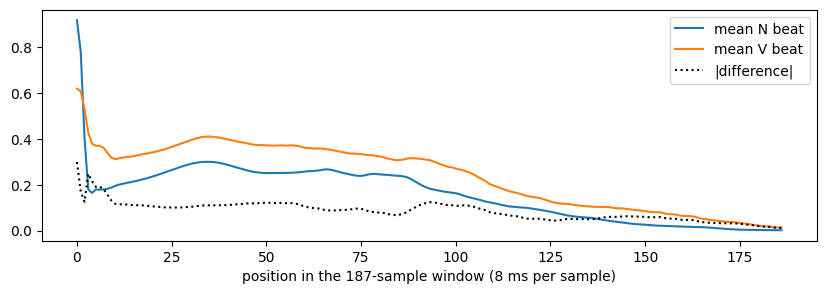

positions of largest N-V difference: [0 3 4 6 5 7 1 8]


In [12]:
mean_n, mean_v = X_te[y_te == 0].mean(0), X_te[y_te == 2].mean(0)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(mean_n, label="mean N beat"); ax.plot(mean_v, label="mean V beat")
ax.plot(np.abs(mean_n - mean_v), "k:", label="|difference|")
ax.set_xlabel("position in the 187-sample window (8 ms per sample)"); ax.legend()
plt.show()
print("positions of largest N-V difference:", np.argsort(-np.abs(mean_n - mean_v))[:8])

### Exercise 2.1 — Gradient and gradient × input

In [13]:
V = CLASSES.index("V")
idx_v = np.flatnonzero((y_te == V) & (pred_te == V))[:200]      # 200 correctly classified V beats
beats_v = X_te[idx_v]


def gradient_map(model, x, c):
    model.eval()
    xb = to_tensor(x).to(DEVICE).requires_grad_(True)
    model(xb)[:, c].sum().backward()
    return xb.grad.squeeze(1).cpu().numpy()


def grad_x_input_map(model, x, c):
    # TODO 2.1: gradient multiplied element-wise by the input
    return gradient_map(model, x, c) * x


g_map = gradient_map(cnn, beats_v, V)
gi_map = grad_x_input_map(cnn, beats_v, V)
check("gradient x input differs from zero", np.abs(gi_map).sum() > 0)

PASS  gradient x input differs from zero


### Exercise 2.2 — Occlusion

In [14]:
@torch.no_grad()
def class_prob(model, x, c):
    model.eval()
    return torch.softmax(model(to_tensor(x).to(DEVICE)), dim=1)[:, c].cpu().numpy()


def occlusion_map(model, x, c, width=10, stride=2):
    base = class_prob(model, x, c)
    total = np.zeros_like(x)
    covered = np.zeros(x.shape[1])
    for start in range(0, x.shape[1] - width + 1, stride):
        # TODO 2.2: copy x, zero the window [start, start + width), compute the probability drop,
        #           add it to total[:, window] and add 1 to covered[window]
        window = slice(start, start + width)
        x_occ = x.copy()
        x_occ[:, window] = 0
        drop = base - class_prob(model, x_occ, c)
        total[:, window] += drop[:, None]
        covered[window] += 1
    return total / np.maximum(covered, 1)


o_map = occlusion_map(cnn, beats_v, V)
check("occlusion found some important positions", o_map.max() > 0.05)

PASS  occlusion found some important positions


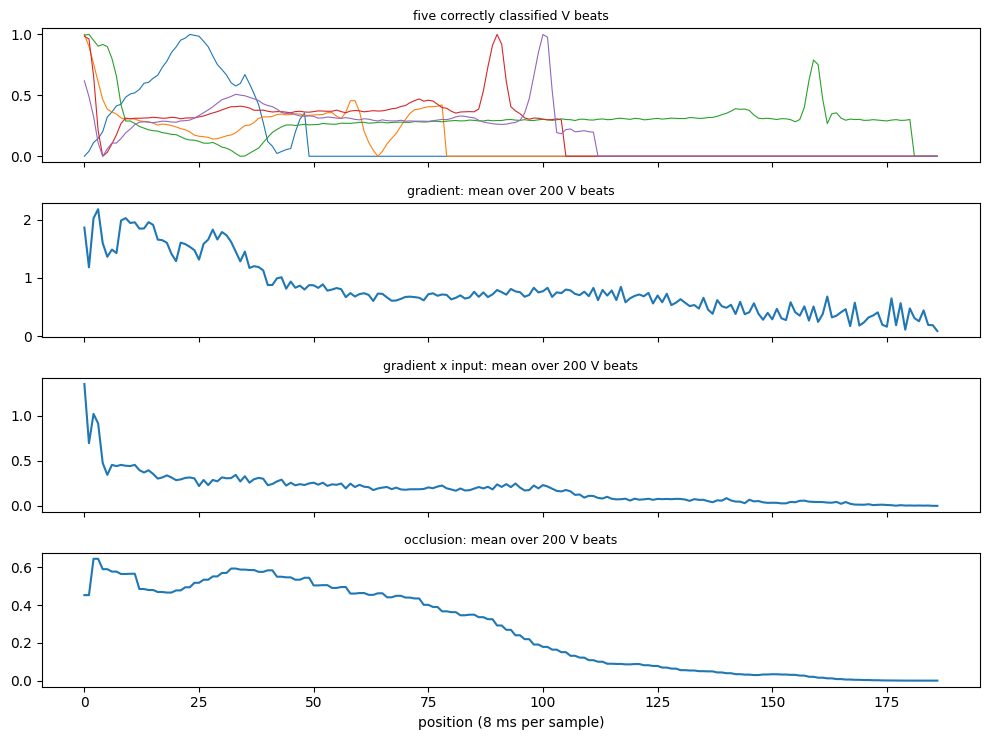

padding is 40% of all positions in these beats


,share of map on padding,top positions
gradient,0.223762,"[3, 9, 2, 8, 14]"
gradient x input,0.0,"[0, 2, 3, 1, 4]"
occlusion,0.001032,"[3, 2, 33, 32, 5]"


In [15]:
def padding_mask(x):
    """True for the zero padding after the last non-zero sample of each beat."""
    last = np.array([np.flatnonzero(r > 0)[-1] if (r > 0).any() else -1 for r in x])
    return np.arange(x.shape[1])[None, :] > last[:, None]


pad = padding_mask(beats_v)
maps = {"gradient": np.abs(g_map), "gradient x input": np.abs(gi_map), "occlusion": np.clip(o_map, 0, None)}
fig, axes = plt.subplots(len(maps) + 1, 1, figsize=(10, 7.5), sharex=True)
axes[0].plot(beats_v[:5].T, lw=0.8); axes[0].set_title("five correctly classified V beats", fontsize=9)
for ax, (name, m) in zip(axes[1:], maps.items()):
    ax.plot(m.mean(0)); ax.set_title(f"{name}: mean over 200 V beats", fontsize=9)
axes[-1].set_xlabel("position (8 ms per sample)")
plt.tight_layout(); plt.show()

summary = pd.DataFrame({name: {"share of map on padding": (m * pad).sum() / m.sum(),
                               "top positions": list(np.argsort(-m.mean(0))[:5])}
                        for name, m in maps.items()}).T
print(f"padding is {pad.mean():.0%} of all positions in these beats")
summary

In [16]:
diff_top = np.argsort(-np.abs(mean_n - mean_v))[:8]
lines = []
for name, m in maps.items():
    tops = np.argsort(-m.mean(0))[:5]
    near = np.mean([np.min(np.abs(diff_top - t)) <= 10 for t in tops])
    share = float(summary.loc[name, "share of map on padding"])
    lines.append(f"{name}: top positions {list(map(int, tops))}, {near:.0%} of them within 10 samples (80 ms) of the largest N-V differences; {share:.1%} of the map is on padding")
nl = lambda items: "\n".join("   - " + i for i in items)
display(Markdown(f"""
**✍️ Answer 2.2**

Where the maps put importance (largest mean N-V differences are at positions {sorted(map(int, diff_top))}; padding is {pad.mean():.0%} of the positions):
{nl(lines)}

Methods that put most of their weight near the large N-V differences are consistent with the data; this is a consistency check, not proof that the model reasons the way a cardiologist would. The gradient map keeps weight on the zero padding because the gradient is a derivative with respect to each input sample, independent of that sample's value: a small change in a padded (zero) position would still change the output through the convolution weights, so it receives a non-zero value. Gradient × input multiplies by the input, which is exactly 0 on padding, so those positions get exactly zero. Occlusion sets a window to 0; where the beat is already 0 nothing changes, so the probability drop is zero there.
"""))


**✍️ Answer 2.2**

Where the maps put importance (largest mean N-V differences are at positions [0, 1, 3, 4, 5, 6, 7, 8]; padding is 40% of the positions):
   - gradient: top positions [3, 9, 2, 8, 14], 100% of them within 10 samples (80 ms) of the largest N-V differences; 22.4% of the map is on padding
   - gradient x input: top positions [0, 2, 3, 1, 4], 100% of them within 10 samples (80 ms) of the largest N-V differences; 0.0% of the map is on padding
   - occlusion: top positions [3, 2, 33, 32, 5], 60% of them within 10 samples (80 ms) of the largest N-V differences; 0.1% of the map is on padding

Methods that put most of their weight near the large N-V differences are consistent with the data; this is a consistency check, not proof that the model reasons the way a cardiologist would. The gradient map keeps weight on the zero padding because the gradient is a derivative with respect to each input sample, independent of that sample's value: a small change in a padded (zero) position would still change the output through the convolution weights, so it receives a non-zero value. Gradient × input multiplies by the input, which is exactly 0 on padding, so those positions get exactly zero. Occlusion sets a window to 0; where the beat is already 0 nothing changes, so the probability drop is zero there.


### Exercise 2.3 — Sanity check: randomise the model

In [17]:
torch.manual_seed(123)
random_cnn = ECGCNN().to(DEVICE).eval()

METHODS = {"gradient": lambda m: np.abs(gradient_map(m, beats_v, V)),
           "gradient x input": lambda m: np.abs(grad_x_input_map(m, beats_v, V)),
           "occlusion": lambda m: occlusion_map(m, beats_v, V)}


def sanity_check(method):
    trained, randomised = METHODS[method](cnn), METHODS[method](random_cnn)
    # TODO 2.3: median over beats of spearmanr(trained[i], randomised[i]).correlation
    cors = [spearmanr(trained[i], randomised[i]).correlation for i in range(len(trained))]
    return float(np.nanmedian(cors))


sanity = pd.Series({name: sanity_check(name) for name in METHODS}, name="median Spearman (trained vs random)")
sanity

,median Spearman (trained vs random)
gradient,0.064403
gradient x input,0.826992
occlusion,-0.708229


In [18]:
failing = [n for n, v in sanity.items() if v > 0.5]
best = sanity.idxmin()
fail_txt = (", ".join(failing) + " (median correlation above 0.5)") if failing else "none clearly (all correlations are low)"
display(Markdown(f"""
**✍️ Answer 2.3**

Median Spearman correlations between trained and random-network maps: {', '.join(f"{n} {v:.2f}" for n, v in sanity.items())}. Methods that fail the sanity check, i.e. whose maps barely change when the weights are randomised: {fail_txt}. Gradient × input can look similar for a trained and a random network because it multiplies the gradient by the input itself: the beat's own shape (large values at the QRS peak, zeros on the padding) dominates the map even when the gradient carries little learned information, so the map partly just reproduces the signal. For this model I would trust **{best}** most, because its map depends the most on the learned weights (lowest correlation with the random model) and it is a direct measurement of what happens to the prediction when part of the beat is removed.
"""))


**✍️ Answer 2.3**

Median Spearman correlations between trained and random-network maps: gradient 0.06, gradient x input 0.83, occlusion -0.71. Methods that fail the sanity check, i.e. whose maps barely change when the weights are randomised: gradient x input (median correlation above 0.5). Gradient × input can look similar for a trained and a random network because it multiplies the gradient by the input itself: the beat's own shape (large values at the QRS peak, zeros on the padding) dominates the map even when the gradient carries little learned information, so the map partly just reproduces the signal. For this model I would trust **occlusion** most, because its map depends the most on the learned weights (lowest correlation with the random model) and it is a direct measurement of what happens to the prediction when part of the beat is removed.


### Exercise 2.4 — Test a suspected shortcut: beat length

In [19]:
def beat_length(x):
    # TODO 2.4a: index of the last non-zero sample + 1, for each beat
    nz = x != 0
    return np.where(nz.any(axis=1), x.shape[1] - np.argmax(nz[:, ::-1], axis=1), 0).astype(float)


len_fit, len_te = beat_length(X_fit), beat_length(X_te)
print(pd.Series(len_te).groupby(pd.Series(y_te).map(dict(enumerate(CLASSES)))).median().rename("median length"))

# TODO 2.4b: logistic regression on length only, V (2) versus N (0); AUROC on the test set
m_fit = np.isin(y_fit, [0, 2]); m_te = np.isin(y_te, [0, 2])
len_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(len_fit[m_fit].reshape(-1, 1), (y_fit[m_fit] == 2).astype(int))
auroc_length = roc_auc_score((y_te[m_te] == 2).astype(int), len_clf.predict_proba(len_te[m_te].reshape(-1, 1))[:, 1])
print("V vs N AUROC from beat length alone:", round(auroc_length, 3))

F     78.0
N    106.0
Q    120.0
S    108.0
V    112.0
Name: median length, dtype: float64
V vs N AUROC from beat length alone: 0.551


In [20]:
med = pd.Series(len_te).groupby(pd.Series(y_te).map(dict(enumerate(CLASSES)))).median()
strength = max(auroc_length, 1 - auroc_length)
verdict = ("a strong shortcut" if strength >= 0.8 else "a moderate shortcut" if strength >= 0.65 else "only a weak shortcut")
others = [c for c in CLASSES if c != "N" and abs(med[c] - med["N"]) >= 10]
oth_txt = (", ".join(f"{c} (median {med[c]:.0f} vs {med['N']:.0f} for N)" for c in others)
           if others else "none: the medians of S, F and Q are all within 10 samples of N's")
display(Markdown(f"""
**✍️ Answer 2.4**

Beat length alone separates V from N with AUROC {auroc_length:.2f}, so it is {verdict} for that pair (0.5 would be no information). Classes whose median length differs clearly from N's: {oth_txt}; for those classes length could act as a shortcut and should be examined separately. This test adds a direct, quantitative answer to "can the model get the label without looking at the waveform?", which saliency maps cannot give: a map shows where the model is sensitive, not what information it could have used instead, and a shortcut such as length can be invisible in a map because the padding position carries the information without looking like part of the beat.
"""))


**✍️ Answer 2.4**

Beat length alone separates V from N with AUROC 0.55, so it is only a weak shortcut for that pair (0.5 would be no information). Classes whose median length differs clearly from N's: F (median 78 vs 106 for N), Q (median 120 vs 106 for N); for those classes length could act as a shortcut and should be examined separately. This test adds a direct, quantitative answer to "can the model get the label without looking at the waveform?", which saliency maps cannot give: a map shows where the model is sensitive, not what information it could have used instead, and a shortcut such as length can be invisible in a map because the padding position carries the information without looking like part of the beat.


## Part 3 — Reflection

In [21]:
display(Markdown(f"""
**✍️ Reflection**

1. A hospital showing SHAP next to each heart-disease risk should first caution that the explanation describes **this model only**: in Part 1 logistic regression and gradient boosting with similar AUROC gave patient 0 risks of {risk_lr:.2f} and {risk_gb:.2f} with different main reasons, so SHAP is not "the reason" the patient has or lacks disease. Second, it should warn that the explanation is about the model's inputs and not causal, and was computed on one site's training data, so on a different population (as in Budapest) the contributions can mislead; clinicians need training, and the explanations should be validated before being displayed at the bedside.
2. For the colleague with the attractive gradient × input map, I would ask them to run the **sanity check first**: randomise the model's weights and show that the map changes. In Part 2 the median trained-vs-random correlation for gradient × input was {sanity['gradient x input']:.2f}, so a map can look convincing while partly just reflecting the input signal. I would also ask for an independent method (occlusion) and for the shortcut test (beat length gave V-vs-N AUROC {auroc_length:.2f}) before accepting "the model looks at the right place".
3. The methods were most useful for **finding problems during development** (and for auditing), not as bedside explanation or proof of correctness. An example from my results: the sanity check and the padding analysis exposed that some maps depend on the input or the padding rather than on what the model learned, and the beat-length test showed whether a shortcut was available. Neither shows that the model is correct, and none of the explanations should be over-claimed as causal.
"""))


**✍️ Reflection**

1. A hospital showing SHAP next to each heart-disease risk should first caution that the explanation describes **this model only**: in Part 1 logistic regression and gradient boosting with similar AUROC gave patient 0 risks of 0.60 and 0.44 with different main reasons, so SHAP is not "the reason" the patient has or lacks disease. Second, it should warn that the explanation is about the model's inputs and not causal, and was computed on one site's training data, so on a different population (as in Budapest) the contributions can mislead; clinicians need training, and the explanations should be validated before being displayed at the bedside.
2. For the colleague with the attractive gradient × input map, I would ask them to run the **sanity check first**: randomise the model's weights and show that the map changes. In Part 2 the median trained-vs-random correlation for gradient × input was 0.83, so a map can look convincing while partly just reflecting the input signal. I would also ask for an independent method (occlusion) and for the shortcut test (beat length gave V-vs-N AUROC 0.55) before accepting "the model looks at the right place".
3. The methods were most useful for **finding problems during development** (and for auditing), not as bedside explanation or proof of correctness. An example from my results: the sanity check and the padding analysis exposed that some maps depend on the input or the padding rather than on what the model learned, and the beat-length test showed whether a shortcut was available. Neither shows that the model is correct, and none of the explanations should be over-claimed as causal.
